# Differentiable factory digital twin

This notebook uses a small pasta factory to show the analyses available from the digital twin: inspect a scenario, simulate inventory and deliveries, assess energy and cost, check capacity, compare what-if scenarios, and measure which production decisions most affect the objective.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch

project_root = Path.cwd()
if not (project_root / 'modules').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from modules.digital_twin import FactoryDigitalTwin
from utils.scenarios import example_parameters

parameters = example_parameters()
twin = FactoryDigitalTwin(parameters)

# Human-readable names make the tensor axes and model inputs explicit.
day_labels = [f'Day {day}' for day in range(1, twin.horizon + 1)]
product_labels = ['Penne', 'Fusilli']
daily_demand_by_day_and_product = parameters.demand
initial_inventory_by_product = parameters.initial_inventory
daily_capacity_by_product = parameters.production_capacity
energy_kwh_per_unit_by_product = parameters.process_energy_per_unit
electricity_tariff_by_day = parameters.tariff

named_input_tensors = {
    'Daily demand (units)': daily_demand_by_day_and_product,
    'Initial inventory (units)': initial_inventory_by_product,
    'Daily capacity (units)': daily_capacity_by_product,
    'Process energy (kWh/unit)': energy_kwh_per_unit_by_product,
    'Electricity tariff (currency/kWh)': electricity_tariff_by_day,
}
named_input_tensors

{'Daily demand (units)': tensor([[30., 10.],
         [10., 25.],
         [20., 20.],
         [35.,  5.],
         [15., 30.],
         [20., 15.],
         [25., 20.]], dtype=torch.float64),
 'Initial inventory (units)': tensor([10.,  5.], dtype=torch.float64),
 'Daily capacity (units)': tensor([45., 35.], dtype=torch.float64),
 'Process energy (kWh/unit)': tensor([0.1600, 0.2200], dtype=torch.float64),
 'Electricity tariff (currency/kWh)': tensor([0.1200, 0.1000, 0.0800, 0.1600, 0.2100, 0.1800, 0.1100],
        dtype=torch.float64)}

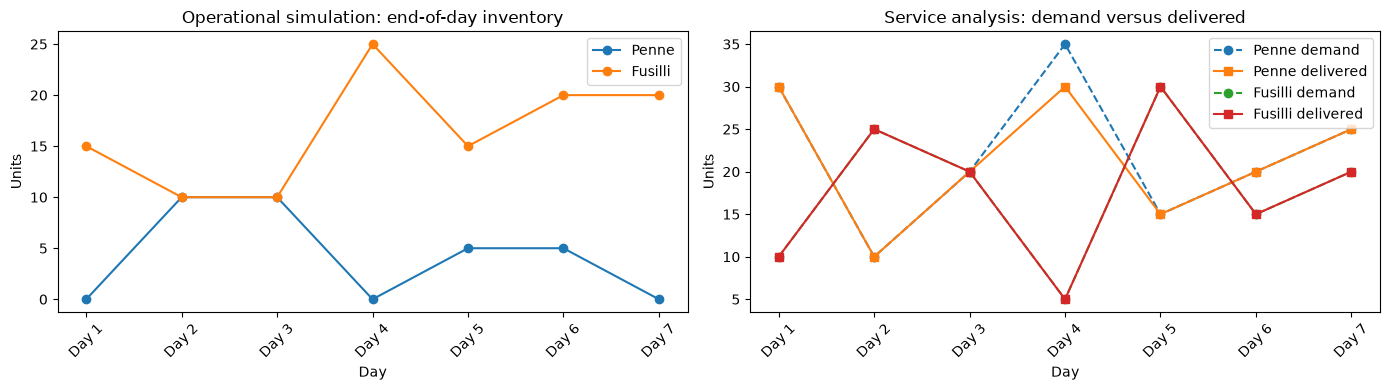

Delivery success rate: 93%
Total unmet demand: 5 units


In [2]:
# Rows are named days; columns are named products.
planned_production_units_by_day_and_product = torch.full(
    (twin.horizon, twin.products), 20.0, dtype=torch.float64, requires_grad=True
)
baseline_result = twin.simulate(planned_production_units_by_day_and_product)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for product_index, product_name in enumerate(product_labels):
    axes[0].plot(day_labels, baseline_result.inventory.detach().numpy()[:, product_index], marker='o', label=product_name)
    axes[1].plot(day_labels, daily_demand_by_day_and_product.numpy()[:, product_index], marker='o', linestyle='--', label=f'{product_name} demand')
    axes[1].plot(day_labels, baseline_result.delivered.detach().numpy()[:, product_index], marker='s', label=f'{product_name} delivered')

axes[0].set(title='Operational simulation: end-of-day inventory', ylabel='Units', xlabel='Day')
axes[1].set(title='Service analysis: demand versus delivered', ylabel='Units', xlabel='Day')
for axis in axes:
    axis.tick_params(axis='x', rotation=45)
    axis.legend()
fig.tight_layout()
plt.show()

print(f'Delivery success rate: {baseline_result.delivery_success_rate.item():.0%}')
print(f'Total unmet demand: {baseline_result.unmet_demand.sum().item():.0f} units')

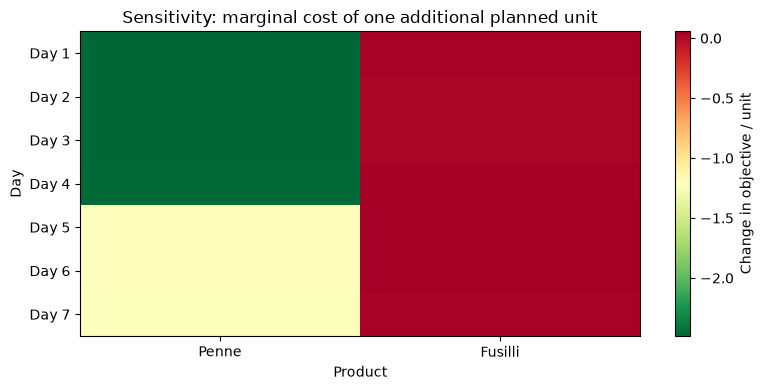

tensor([[-2.4760,  0.0326],
        [-2.4800,  0.0272],
        [-2.4840,  0.0217],
        [-2.4680,  0.0435],
        [-1.2080,  0.0570],
        [-1.2140,  0.0489],
        [-1.2280,  0.0299]], dtype=torch.float64)

In [3]:
# The energy and delivery objective is differentiable with respect to every planned quantity.
penalised_objective = twin.objective(planned_production_units_by_day_and_product, capacity_penalty=100.0)
penalised_objective.backward()
marginal_cost_by_day_and_product = planned_production_units_by_day_and_product.grad.detach()

fig, axis = plt.subplots(figsize=(8, 4))
gradient_image = axis.imshow(marginal_cost_by_day_and_product.numpy(), cmap='RdYlGn_r', aspect='auto')
axis.set(title='Sensitivity: marginal cost of one additional planned unit', xlabel='Product', ylabel='Day',
         xticks=range(twin.products), xticklabels=product_labels,
         yticks=range(twin.horizon), yticklabels=day_labels)
fig.colorbar(gradient_image, ax=axis, label='Change in objective / unit')
fig.tight_layout()
plt.show()

marginal_cost_by_day_and_product

## Scenario analysis

Inspect demand, starting stock, and the changing electricity price before choosing a plan. These visual assumptions drive every analysis below.

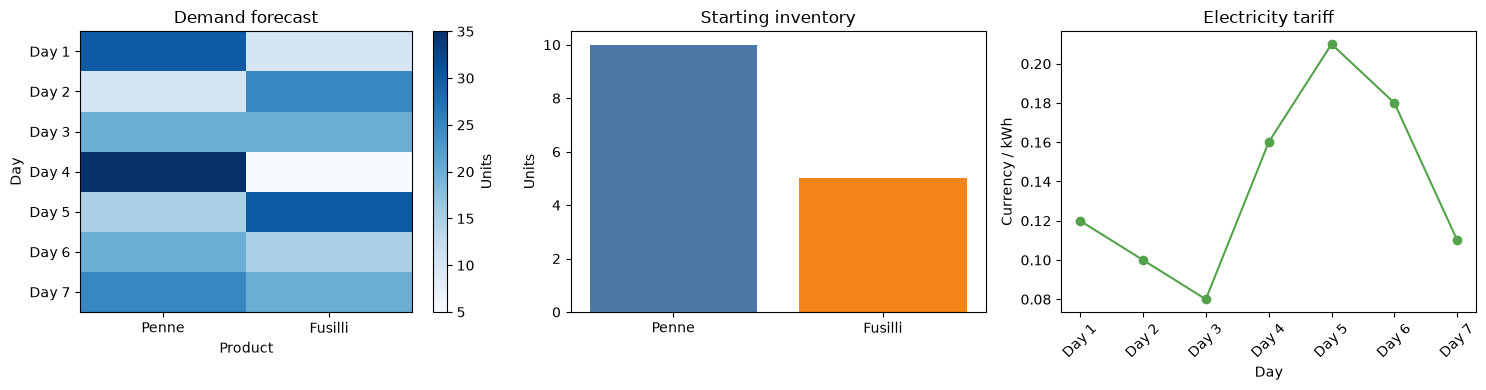

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
demand_image = axes[0].imshow(daily_demand_by_day_and_product.numpy(), cmap='Blues', aspect='auto')
axes[0].set(title='Demand forecast', xticks=range(twin.products), xticklabels=product_labels,
            yticks=range(twin.horizon), yticklabels=day_labels, xlabel='Product', ylabel='Day')
fig.colorbar(demand_image, ax=axes[0], label='Units')
axes[1].bar(product_labels, initial_inventory_by_product.numpy(), color=['#4C78A8', '#F58518'])
axes[1].set(title='Starting inventory', ylabel='Units')
axes[2].plot(day_labels, electricity_tariff_by_day.numpy(), marker='o', color='#54A24B')
axes[2].set(title='Electricity tariff', ylabel='Currency / kWh', xlabel='Day')
axes[2].tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

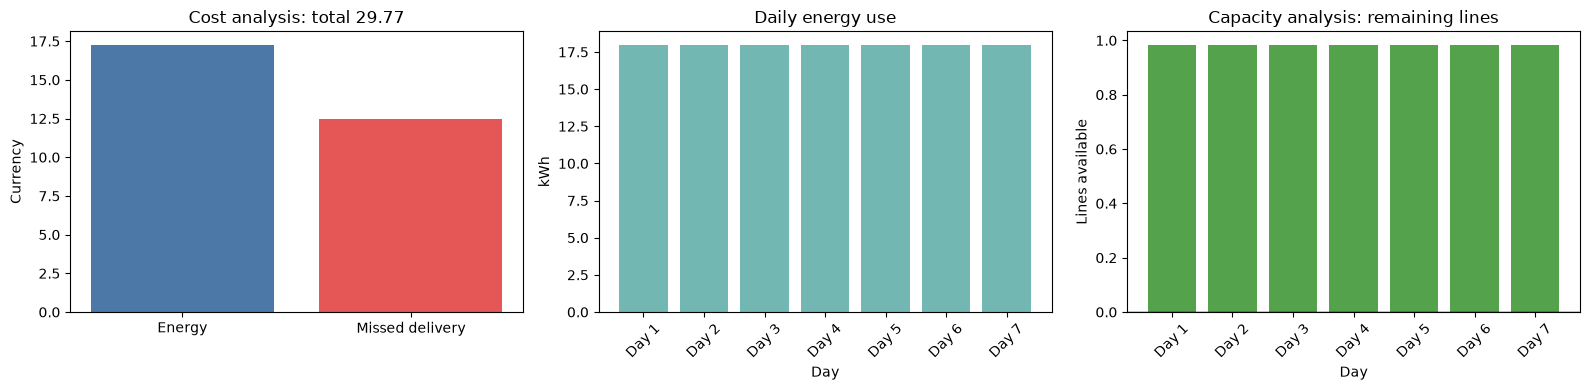

In [5]:
# Cost, energy, and feasibility analysis use the same simulated result.
remaining_line_capacity_by_day = twin.capacity_constraints(planned_production_units_by_day_and_product).detach()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(['Energy', 'Missed delivery'], [baseline_result.energy_cost.item(), baseline_result.failure_cost.item()], color=['#4C78A8', '#E45756'])
axes[0].set(title=f'Cost analysis: total {baseline_result.total_cost.item():.2f}', ylabel='Currency')
axes[1].bar(day_labels, baseline_result.energy_kwh.detach().numpy(), color='#72B7B2')
axes[1].set(title='Daily energy use', ylabel='kWh', xlabel='Day')
axes[1].tick_params(axis='x', rotation=45)
capacity_colors = ['#54A24B' if value >= 0 else '#E45756' for value in remaining_line_capacity_by_day.numpy()]
axes[2].bar(day_labels, remaining_line_capacity_by_day.numpy(), color=capacity_colors)
axes[2].axhline(0, color='black', linewidth=1)
axes[2].set(title='Capacity analysis: remaining lines', ylabel='Lines available', xlabel='Day')
axes[2].tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

## What-if and resilience analysis

Test a disruption without affecting the factory. A one-day Penne demand spike is compared with the baseline plan, revealing its service and cost impact.

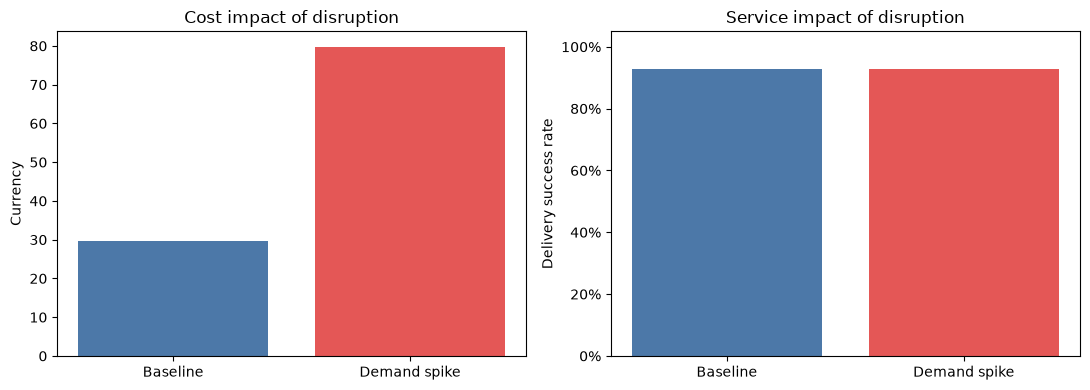

In [6]:
from dataclasses import replace

spike_day_index = 3
demand_spike_units_by_day_and_product = daily_demand_by_day_and_product.clone()
demand_spike_units_by_day_and_product[spike_day_index, 0] += 20
spike_parameters = replace(parameters, demand=demand_spike_units_by_day_and_product)
spike_result = FactoryDigitalTwin(spike_parameters).simulate(planned_production_units_by_day_and_product.detach())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scenario_names = ['Baseline', 'Demand spike']
axes[0].bar(scenario_names, [baseline_result.total_cost.item(), spike_result.total_cost.item()], color=['#4C78A8', '#E45756'])
axes[0].set(title='Cost impact of disruption', ylabel='Currency')
axes[1].bar(scenario_names, [baseline_result.delivery_success_rate.item(), spike_result.delivery_success_rate.item()], color=['#4C78A8', '#E45756'])
axes[1].set(title='Service impact of disruption', ylabel='Delivery success rate', ylim=(0, 1.05))
axes[1].yaxis.set_major_formatter('{x:.0%}')
fig.tight_layout()
plt.show()